# Scikit-learn: custom components and model selection

1. A **k-nearest neighbours classifier written from scratch** (see [`sklearn/`](sklearn/)),
   checked against scikit-learn's implementation.
2. A **monthly time-series cross-validator**, and why shuffled cross-validation overestimates
   performance on time series.
3. **Model selection** with pipelines and grid search over several classifiers and regressors.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_diabetes, make_classification, make_moons
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import ElasticNet, Lasso, LogisticRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, "sklearn")
from sklearn_questions import KNearestNeighbors, MonthlySplit  # noqa: E402

## 1. k-NN from scratch

`KNearestNeighbors` follows the scikit-learn estimator API (`fit` / `predict` / `score`,
input validation, `check_estimator` compliant), so it plugs into pipelines and grid search.

In [2]:
X, y = make_classification(n_samples=600, n_features=20, n_informative=8, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

rows = []
for k in [1, 3, 5, 7, 15]:
    ours = KNearestNeighbors(n_neighbors=k).fit(X_train, y_train)
    ref = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    rows.append({
        "k": k,
        "accuracy (ours)": ours.score(X_test, y_test),
        "accuracy (sklearn)": ref.score(X_test, y_test),
        "same predictions": (ours.predict(X_test) == ref.predict(X_test)).mean(),
    })
pd.DataFrame(rows).set_index("k")

,accuracy (ours),accuracy (sklearn),same predictions
k,,,
1,0.820000,0.820000,1.0
3,0.880000,0.880000,1.0
5,0.900000,0.900000,1.0
7,0.880000,0.880000,1.0
15,0.853333,0.853333,1.0


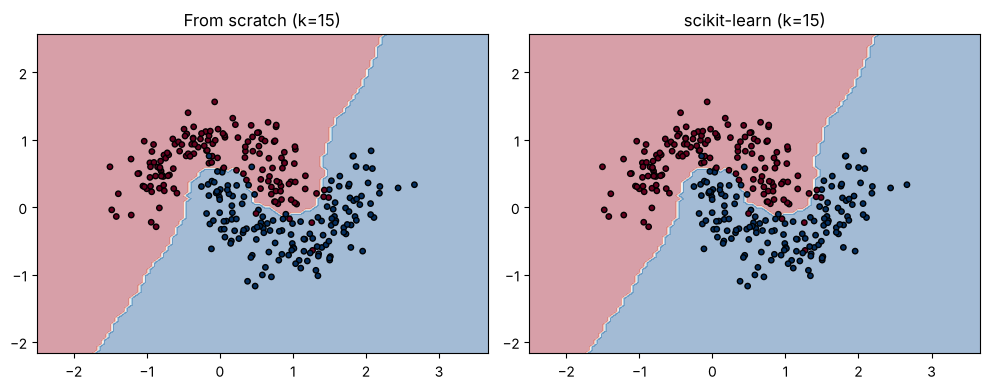

In [3]:
# Same decision boundary on a non-linear 2D problem
Xm, ym = make_moons(n_samples=300, noise=0.25, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, model, title in [
    (axes[0], KNearestNeighbors(n_neighbors=15), "From scratch"),
    (axes[1], KNeighborsClassifier(n_neighbors=15), "scikit-learn"),
]:
    model.fit(Xm, ym)
    DecisionBoundaryDisplay.from_estimator(model, Xm, ax=ax, alpha=0.4, cmap="RdBu", response_method="predict")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="RdBu", edgecolor="k", s=15)
    ax.set_title(f"{title} (k=15)")
plt.tight_layout()

In [4]:
# The loop-based implementation is clear but slower than sklearn's optimised one
for model in [KNearestNeighbors(5), KNeighborsClassifier(5)]:
    start = time.perf_counter()
    model.fit(X_train, y_train).predict(X_test)
    print(f"{type(model).__name__:22s} {1000 * (time.perf_counter() - start):6.1f} ms")

KNearestNeighbors        52.5 ms
KNeighborsClassifier      1.8 ms


## 2. Time-series cross-validation

`MonthlySplit` trains on one month and tests on the next, so the model never sees the
future. With a shuffled `KFold`, neighbouring (highly correlated) days end up in both the
training and the test set, and the score is overly optimistic.

In [5]:
rng = np.random.default_rng(0)
dates = pd.date_range("2022-01-01", "2022-12-31", freq="D")
# A slowly drifting signal plus noise: today's value is close to yesterday's
level = np.cumsum(rng.normal(0, 1, len(dates)))
series = pd.DataFrame({"value": level + rng.normal(0, 0.5, len(dates))}, index=dates)
for lag in [1, 2, 7]:
    series[f"lag_{lag}"] = series["value"].shift(lag)
series["day_of_year"] = series.index.dayofyear
series = series.dropna()

X_ts, y_ts = series.drop(columns="value"), series["value"]
cv = MonthlySplit(time_col="index")
print(f"{cv.get_n_splits(X_ts)} monthly splits")

11 monthly splits


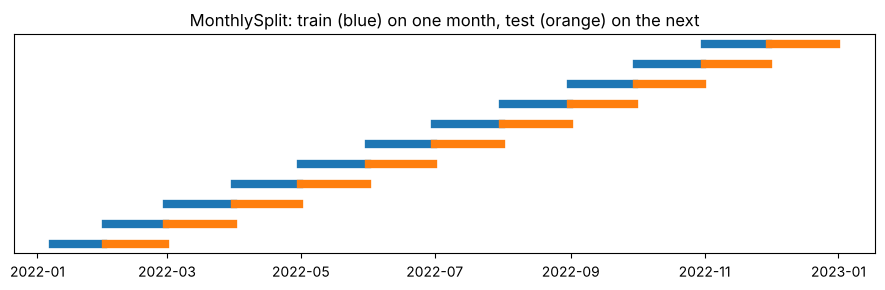

In [6]:
fig, ax = plt.subplots(figsize=(9, 3))
for i, (train_idx, test_idx) in enumerate(cv.split(X_ts, y_ts)):
    ax.plot(X_ts.index[train_idx], [i] * len(train_idx), color="tab:blue", lw=6)
    ax.plot(X_ts.index[test_idx], [i] * len(test_idx), color="tab:orange", lw=6)
ax.set_yticks([]); ax.set_title("MonthlySplit: train (blue) on one month, test (orange) on the next")
plt.tight_layout()

In [7]:
from sklearn.metrics import make_scorer, mean_absolute_error

mae = make_scorer(mean_absolute_error)
naive_mae = mean_absolute_error(y_ts, X_ts["lag_1"])   # baseline: tomorrow = today

rows = []
for name, model in [("ridge", Ridge()), ("random_forest", RandomForestRegressor(n_estimators=100, random_state=0))]:
    rows.append({
        "model": name,
        "MAE, shuffled KFold": cross_val_score(model, X_ts, y_ts, cv=KFold(5, shuffle=True, random_state=0), scoring=mae).mean(),
        "MAE, MonthlySplit": cross_val_score(model, X_ts, y_ts, cv=cv, scoring=mae).mean(),
    })
table = pd.DataFrame(rows).set_index("model")
table.loc["naive (tomorrow = today)"] = naive_mae
table.round(2)

,"MAE, shuffled KFold","MAE, MonthlySplit"
model,,
ridge,0.97,3.13
random_forest,1.00,2.40
naive (tomorrow = today),0.98,0.98


With shuffled folds both models look **as good as the naive forecast** (MAE around 1): the
training set contains the days just before and after each test day, so they only have to
interpolate. Evaluated the way they would actually be used, on the next month, their error is
**2.5 to 3 times larger than the naive forecast**: the random forest
cannot extrapolate to price levels it has never seen, and the linear model overfits the day of the
year. Shuffled cross-validation would have led to deploying a model that destroys value.

## 3. Model selection with pipelines

Every model sits in a pipeline with the scaler, so scaling is fitted on the training folds
only. Grid search picks hyper-parameters by 5-fold cross-validation; the held-out test set is
used once at the end.

In [8]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

classifiers = {
    "logistic_regression": (LogisticRegression(max_iter=5000), {"clf__C": [0.1, 1, 10]}),
    "svc": (SVC(), {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"]}),
    "random_forest": (RandomForestClassifier(random_state=0), {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 10]}),
    "gradient_boosting": (GradientBoostingClassifier(random_state=0), {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
    "knn": (KNeighborsClassifier(), {"clf__n_neighbors": [3, 5, 7], "clf__weights": ["uniform", "distance"]}),
    "knn_from_scratch": (KNearestNeighbors(), {"clf__n_neighbors": [3, 5, 7]}),
    "decision_tree": (DecisionTreeClassifier(random_state=0), {"clf__max_depth": [3, 5, None]}),
}

results = []
for name, (estimator, grid) in classifiers.items():
    search = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("clf", estimator)]), grid, cv=5, scoring="accuracy")
    search.fit(X_train, y_train)
    results.append({"model": name, "cv accuracy": search.best_score_,
                    "test accuracy": search.score(X_test, y_test),
                    "best params": {k.removeprefix("clf__"): v for k, v in search.best_params_.items()}})
pd.DataFrame(results).set_index("model").sort_values("cv accuracy", ascending=False).round(3)

,cv accuracy,test accuracy,best params
model,,,
logistic_regression,0.980,0.974,{'C': 0.1}
svc,0.978,0.982,"{'C': 0.1, 'kernel': 'linear'}"
knn,0.971,0.974,"{'n_neighbors': 7, 'weights': 'uniform'}"
knn_from_scratch,0.971,0.974,{'n_neighbors': 7}
gradient_boosting,0.967,0.947,"{'learning_rate': 0.1, 'max_depth': 2}"
random_forest,0.960,0.956,"{'max_depth': None, 'n_estimators': 300}"
decision_tree,0.938,0.930,{'max_depth': 5}


In [9]:
X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressors = {
    "ridge": (Ridge(), {"clf__alpha": [0.1, 1, 10, 100]}),
    "lasso": (Lasso(max_iter=10_000), {"clf__alpha": [0.01, 0.1, 1]}),
    "elasticnet": (ElasticNet(max_iter=10_000), {"clf__alpha": [0.01, 0.1, 1], "clf__l1_ratio": [0.2, 0.5, 0.8]}),
    "random_forest": (RandomForestRegressor(random_state=0), {"clf__n_estimators": [200], "clf__min_samples_leaf": [1, 5, 10]}),
    "knn": (KNeighborsRegressor(), {"clf__n_neighbors": [5, 10, 20], "clf__weights": ["uniform", "distance"]}),
}

results = []
for name, (estimator, grid) in regressors.items():
    search = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("clf", estimator)]), grid, cv=5, scoring="r2")
    search.fit(X_train, y_train)
    results.append({"model": name, "cv R2": search.best_score_, "test R2": search.score(X_test, y_test),
                    "best params": {k.removeprefix("clf__"): v for k, v in search.best_params_.items()}})
pd.DataFrame(results).set_index("model").sort_values("cv R2", ascending=False).round(3)

,cv R2,test R2,best params
model,,,
elasticnet,0.456,0.460,"{'alpha': 0.1, 'l1_ratio': 0.2}"
lasso,0.454,0.467,{'alpha': 1}
ridge,0.454,0.457,{'alpha': 10}
random_forest,0.419,0.480,"{'min_samples_leaf': 10, 'n_estimators': 200}"
knn,0.403,0.436,"{'n_neighbors': 20, 'weights': 'distance'}"


On this small dataset (442 patients, 10 features) the regularised linear models are as good
as the random forest: more flexible models do not help when the signal is mostly linear and
the sample is small.